# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі запускаємо локально через [Ollama](https://ollama.com) і звертаємося до нього звичайними HTTP-запитами.

# Відповіді на питання по демо

1. Слово "трансформер" розбивається на кілька підслівних токенів. Буква "р" опиняється всередині них і окремо для моделі не видна. В моделях під час тренування рахувати  майже не вчать. Для української воно виражене сильніше, бо кирилиця представлена в корпусі гірше за англійську. Міркування не лікує проблему, бо модель послідовно генерує текст, але вихідні дані для цього тексту так само йдуть з токенів.  
2. Від fp16 до int8 перплексія не змінюється, а chrF і BLEU залишаються на рівні fp16. На int4 вона трохи зростає, а переклад ще працює. На int2 модель ламається: перплексія зашкалює. Найбільший стрибок між int4 та int2. Причина в тому, що в 2-бітних вагах лінійних шарів лише 4 можливі значення, тому похибка накопичується й модель починає видавати незв'язні передбачення.
3. Ні, не однаково. На int4 перплексія зростає на 5% для англійської і на 15% для української.Українська деградує швидше, бо вона менше представлена в навчальних даних і гірше токенізується, тож похибки квантизації накопичуються сильніше. Порівнювати треба саме відносне зростання, бо абсолютні значення перплексії між мовами непорівнянні.
4. Між fp16 та int4 метрики змінилися лише трохи, а в генераціях різниця помітна: відповіді int4 коротші, спрощені, з дрібними стилістичними огріхами. Тобто око вловлює втрату якості раніше, ніж перплексія й метрики перекладу, особливо в українській.
5. Приклад: "Наша команда виправила баг, але тестування все ще…" замість еталонного "виправила помилку… тести". Переклад правильний, але слова інші. BLEU штрафує сильно, бо рахує збіги цілих слів і синонім для нього просто помилка. chrF штрафує значно м'якше, бо порівнює символьні n-грами, і частина збігається ("тест", "виправила"). chrF вищий за BLEU для правильних, але вільних перекладів.
6. Квантизуються лише ваги nn.Linear, а ембединги, нормалізації та вихідний шар лишаються в fp16; + додається службова інформація. Чим менше бітів, тим більший внесок цієї незмінної частини. Генерація не прискорилася, а сповільнилася: fp16 найшвидша, квантизовані варіанти помітно повільніші. T4 не вміє множити цілі числа напряму, тому ваги щоразу розпаковуються в 16 біт, а на int4/int2 розпаковка ще й виконується на PyTorch.
7. Base-модель лише продовжує текст, а не виконує інструкції. Наданий рядок виглядає як рядок зі списку питань вікторини, тому найімовірніше продовження - наступні питання. Щоб отримати відповідь, треба задати шаблон, у якому після питання очікується відповідь.
8. Режим міркування згенерував приблизно в 2–2.5 раза більше токенів і витратив стільки ж більше часу, ніж відповідь без міркувань, при однаковій правильній відповіді. Користувач бачить результат лише після завершення міркувань. Англійською модель міркує тому, що Qwen3 донавчали на ланцюжках міркувань переважно англійською, тож "внутрішній монолог" за замовчуванням англомовний, незалежно від мови питання. Мова фінальної відповіді при цьому відповідає мові запиту.
9. Відповідь з міркуванням скоріше за все вірна, бо звичайна модель просто запам'ятала схожу задачу, де питаєтсья про кілограм і того, і того, а думаюча модель змогла виокремити числа і порівняти їх
10. temperature: 0 вимикає випадковість: модель завжди бере найімовірніший токен, тож на той самий запит відповідь однакова. seed: 1 фіксує генератор випадкових чисел на випадок, якщо десь лишається семплінг. Разом це дає відтворюваний результат і чесне порівняння режимів (think/no-think, Base/Instruct): різниця між відповідями зумовлена моделлю чи промптом, а не випадковістю.
11. T4 має архітектуру Turing, і torch.cuda.get_device_capability() повертає (7, 5). Апаратна підтримка bf16 з'являється з compute capability 8.0 (Ampere: A100, RTX 30xx і новіші), тож T4 її не має, і bf16 там або недоступний, або емулюється. fp16 T4 підтримує нативно.
12. Qwen3-4B-Instruct-2507 має приблизно 4 млрд параметрів. За формулою «кількість параметрів x байтів на параметр» fp16 (2 байти) дає приблизно 8 ГБ. У таблиці розділу 2.4 для fp16 памʼять моделі також близько 8 ГБ, тобто теорія й практика збігаються. Для квантизованих варіантів вона вже не збігається, бо частина модель лишається в 16 бітах. Також "памʼять моделі" в таблиці рахує лише ваги, а пік VRAM більший за рахунок активацій і KV-кешу.
13. Перплексія показує, наскільки модель "здивована" текстом: це експонента від середньої похибки передбачення наступного токена, тобто грубо кількість варіантів, з яких модель у середньому вагається. Чим менша, тим краще модель знає мову й тему. Порівнювати її між англійською та українською не можна, бо токенізація різна: українське слово ділиться на більше токенів, а перплексія рахується на токен, а не на слово чи символ. Тексти також різні за складністю й змістом. Перплексія на випадковому наборі слів буде значно вищою: модель не може передбачити наступне слово без звʼязного контексту, тож розподіл імовірностей "розмивається". Це показує, що метрика вимірює розуміння структури й змісту мови, а не просто знання слів.
14. Памʼять моделі рахує лише ваги, а пік VRAM фіксує максимум за весь час, включно із завантаженням і генерацією. Крім ваг, памʼять займають: KV-кеш (ключі й значення уваги для всіх уже оброблених токенів, росте з довжиною тексту), активації проміжних шарів, логіти розміром "довжина x словник" та тимчасові буфери, зокрема розпаковані 16-бітні ваги при квантизації.
15. fp16 - 2 рази, int4 - 3 рази. Висновки з 5 порівнянь робити не можна: навіть рахунок 5:0 дав би p близько 0.06 (статистично недостовірно). Щоб надійно виявити перевагу в 70% на користь одного варіанта, потрібно приблизно 50 порівнянь, а для різниці 60% на 40% близько 200. Краще також брати різні запити, кількох оцінщіків.
16. У int2 генерація повністю руйнується, відповіді не стосуються запиту: це набір випадкових символів, обривків слів і розділових знаків, змішані мови. Часто модель зациклюється на одному токені чи символі і не зупиняється до ліміту токенів. Це узгоджується з перплексією, що вибухає.
В int4 такого збою немає, але ознаки деградації вже помітні, передусім у перекладі й українській мові: смислові помилки, відповіді коротші й спрощені, інколи дивні звороти. Частина огріхів трапляється й у fp16, тож це обмеження самої 4B-моделі, а не лише квантизації. В англійських запитах int4 майже не відрізняється від fp16.
17. На int8 обидві моделі практично не втрачають якість: перплексія майже не змінюється, а невеликі коливання chrF лежать у межах шуму вибірки з 10 речень. На int4 картина розходиться. У 4B перплексія зростає на кілька відсотків (трохи більше для української), а переклад зберігається. У 1.7B перплексія зростає майже вдвічі для обох мов, chrF падає приблизно на 40%, а BLEU майже до нуля. Мала модель має менше надлишковості у вагах, тому 4 біти для неї вже занадто грубі, а для 4B ще прийнятні. Модель 1.7B слабша й без квантизації (вища перплексія, нижчий chrF), тож квантизація погіршує й так гіршу базу. На int2 ламаються обидві моделі.
Економія памʼяті в 1.7B менша, ніж у 4B (на int2 приблизно x3 проти x4.5), бо ембединги й вихідний шар лишаються в 16 бітах, а в меншій моделі вони складають більшу частку параметрів.
18. OLLAMA_NUM_PARALLEL задає, скільки запитів Ollama обробляє одночасно для однієї завантаженої моделі. Ваги завантажуються в памʼять один раз, а для кожного паралельного "слота" виділяється окремий KV-кеш. Тому памʼять росте приблизно пропорційно (контекст x кількість слотів). Збільшення параметра підвищує загальну пропускну здатність, коли запитів багато, але може трохи збільшити затримку на кожен запит і ризикує вичерпати VRAM.
19. bf16 має 8 біт на порядок (як fp32) і лише 7 біт мантиси. Діапазон значень такий самий, як у fp32, тому при навчанні не виникає переповнення чи зникання градієнтів і не потрібне масштабування втрат, як у fp16. Меншу точність нейромережі переживають без втрат якості. Памʼять вдвічі менша за fp32, а конвертація fp32 між bf16 проста (відкидання молодших біт). Сучасні прискорювачі нативно підтримують bf16 і моделі навчають саме в ньому, тож зберігання у bf16 не додає втрат від конвертації.
20. Формат запитів OpenAI (/v1/chat/completions) став стандартом, бо ChatGPT і його API першими здобули масову популярність, і навколо нього зʼявилася ціла екосистема клієнтів: SDK, LangChain, плагіни для IDE та інші застосунки. Рантайми (Ollama, vLLM, llama.cpp, LM Studio) реалізують сумісний ендпоінт, тож будь-який такий клієнт працює з ними без змін: достатньо змінити base_url і назву моделі. Це знижує залежність від одного постачальника й дозволяє легко перемикатися між хмарною та локальною моделлю.

In [ ]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("Qwen/Qwen3-1.7B")
word = "трансформер"

ids = tok(word, add_special_tokens=False).input_ids
pieces = [tok.decode([i]) for i in ids]
print("Токени:", pieces, ids)
print("Літер у слові:", len(word), "| токенів:", len(ids))
print("Літер \"р\" у кожному токені:", [p.count("р") for p in pieces])
print("Правильна відповідь:", word.count("р"))

spaced = " ".join(word)
ids2 = tok(spaced, add_special_tokens=False).input_ids
print("По літерах:", [tok.decode([i]) for i in ids2], "| токенів:", len(ids2))

Токени: ['т', 'ран', 'с', 'форм', 'ер'] [1792, 34582, 2247, 56619, 7599]
Літер у слові: 11 | токенів: 5
Літер "р" у кожному токені: [0, 1, 0, 1, 1]
Правильна відповідь: 3
По літерах: ['т', ' р', ' а', ' н', ' с', ' ф', ' о', ' р', ' м', ' е', ' р'] | токенів: 11


#Звіт
### Залізо

| Компонент | Значення |
|---|---|
| GPU | NVIDIA GeForce RTX 4070, 12 ГБ GDDR6X (12282 MiB) |
| Пропускна здатність VRAM | 504 ГБ/с (192 біт × 21 Гбіт/с / 8) |
| CPU | AMD Ryzen 9 9900X, 12 ядер / 24 потоки |
| RAM | 32 ГБ DDR5-6000 CL30, 2 канали |
| Пропускна здатність RAM | 96 ГБ/с (2 канали × 8 Б × 6000 МТ/с) |
| VRAM, зайнята системою без моделі | близько 2280 MiB |

Дані взяті з nvidia-smi, lscpu, sudo dmidecode -t memory

### Розрахунок

**Бюджет VRAM:** 12282 − 2280 = 10002 MiB ≈ 10.5 ГБ.

**Формули:**

    Memory = P × (Q / 8) × (1 + Overhead)
    Memory = ваги + KV + запас
    KV = 2 × шарів × KV-голів × head_dim × контекст × 2 Б
    стеля швидкості (tok/s) = пропускна здатність / розмір ваг

**KV-кеш Qwen3-8B** (36 шарів, 8 KV-голів, head_dim 128, контекст 8192):
2 × 36 × 8 × 128 × 2 Б = 147 456 Б на токен; 147 456 × 8192 ≈ 1.21 ГБ.
Контекст 8192 обрано тому, що типові запити в застосунку короткі, а більший контекст збільшує KV-кеш лінійно.

**Розмір ваг** береться з розміру GGUF-файлу (8.2B параметрів).
Overhead у формулі калькулятора: 20%. Запас рантайму в явній формулі: 1 ГБ.

| Варіант | Ваги, ГБ | Калькулятор: ваги × 1.2 | Явна: ваги + 1.21 + 1.0 | Влізає в 10.49 ГБ | Стеля: 504 / ваги |
|---|---|---|---|---|---|
| Q8_0 | 8.71 | 10.45 | 10.92 | на межі | 57.9 tok/s |
| Q6_K | 6.73 | 8.08 | 8.94 | так | 74.9 tok/s |
| Q4_K_M | 5.03 | 6.04 | 7.24 | так | 100.2 tok/s |

Оцінка для більших моделей: Qwen3-14B у Q4_K_M ≈ 9.0 ГБ ваг + 1.3 ГБ KV + 1 ГБ запасу ≈ 11.3 ГБ.

Для Q8_0 формули дають різний результат, бо відсоток overhead росте разом із вагами, а KV-кеш від розміру ваг не залежить.
Остаточна перевірка зроблена завантаженням: з Q8_0 nvidia-smi показала 11300 MiB з 12282 MiB, з Q4_K_M 8310 MiB. Обидва варіанти повністю вмістилися на GPU.

### Обрана модель, квантизація й рантайм і чому

- **Модель:** Qwen3-8B (8.2B параметрів). Найбільша щільна модель, що вміщається у VRAM разом із KV-кешем на 8192 токени.
- **Instruct чи ні:** Instruct (post-trained) версія, бо застосунку потрібні відповіді на запити, а Base-модель лише продовжує текст.
- **Міркування:** вимкнене через /no_think у промптах,для коротких відповідей воно дає лише зайві токени й затримку.
- **Формат і рантайм:** GGUF у LM Studio. LM Studio працює на llama.cpp, підтримує GGUF і віддає OpenAI-сумісний API на localhost:1234.
- **Квантизація:** Q8_0 як базова точка, Q4_K_M як оптимізація.
- **Налаштування однакові в обох запусках:** контекст 8192, GPU Offload 36, Max Concurrent Predictions 4.

### Вимірювання до оптимізації

bench.py, мітка before, модель qwen3-8b@q8_0, 16 запитів на рівень, ті самі 8 промптів з /no_think, reasoning=False, помилок немає.

| Клієнтів | TTFT p50, с | TTFT p95, с | tok/s на користувача | Throughput, tok/s |
|---|---|---|---|---|
| 1 | 0.121 | 0.124 | 50.2 | 48.4 |
| 2 | 0.150 | 0.204 | 47.4 | 84.0 |
| 4 | 0.175 | 0.201 | 43.7 | 145.4 |
| 8 | 2.338 | 3.967 | 44.1 | 145.6 |

Порівняння з прогнозом: виміряно 50.2 tok/s при прогнозованій стелі у 57.9. Розбіжність можна пояснити тим, що на кожен токен, крім ваг, читається KV-кеш, а також додаються витрати рантайму та системи.

### Оптимізація і вимірювання після

Зміна: Q8_0 -> Q4_K_M, решта налаштувань без змін. Мітка after, модель qwen3-8b@q4_k_m.

| Клієнтів | TTFT p50, с | TTFT p95, с | tok/s на користувача | Throughput, tok/s |
|---|---|---|---|---|
| 1 | 0.084 | 0.087 | 80.2 | 77.0 |
| 2 | 0.109 | 0.152 | 73.0 | 132.3 |
| 4 | 0.131 | 0.179 | 64.4 | 219.5 |
| 8 | 1.803 | 3.081 | 65.5 | 211.3 |

- Швидкість одного користувача: 50.2 -> 80.2 tok/s (1.60x), прогноз за відношенням розмірів ваг 8.71 / 5.03 = 1.73x. Частка від стелі: 80% (стеля 100.2).
- TTFT p50 при 1 клієнті: 0.121 -> 0.084 с.
- Максимальний throughput: 145.6 -> 219.5 tok/s.
- При 8 клієнтах throughput перестає рости, а TTFT різко зростає: LM Studio обробляє одночасно 4 запити (Max Concurrent Predictions = 4), решта чекає в черзі, і цей час потрапляє в TTFT.
- Перевірка якості: промпти для застосунку це 21 дія гравця з demo/rpg_bench.mjs, які проходять один сценарій зачистки підземелля (кидки d20 задані наперед і однакові для обох моделей). Щоб висновок не залежав від одного випадкового прогону, скрипт demo/rpg_bench_many.mjs запустив цей бенчмарк по 20 разів для кожної моделі (параметри генерації ті самі, що в застосунку).

| Показник (20 запусків) | Q8_0 | Q4_K_M |
|---|---|---|
| Гру пройдено до перемоги | 10 з 20 | 20 з 20 |
| Цілей виконано, середнє (з 3) | 2.50 | 3.00 |
| Правильну ціль названо | 100 з 130 (77%) | 116 з 120 (97%) |
| Неможливі дії розпізнано | 40 з 40 | 40 з 40 |
| Звичайні дії хибно визнано неможливими | 0 | 0 |
| Повторні запити через зламаний JSON | 0 | 0 |
| Ходи з китайськими символами | 0 | 2 |
| Тверджень моделі відхилено кодом, середнє за гру | 2.60 | 2.95 |
| Кінцевий HP, середнє | 13.45 | 14.00 |
| Середній час ходу, с (мін-макс) | 4.22 (3.9-4.5) | 2.74 (2.6-2.9) |

- Швидкість: хід у Q4_K_M у 1.54 раза швидший, розкид малий в обох моделей, тож різниця надійна.
- Проходження гри: Q4_K_M виграв усі 20 запусків. Q8_0 виграв 10 із 20, в інших за 21 хід виконав 2 цілі з 3 (персонаж не гинув). Оцінка дії в Q8_0 частіше називає не ту ціль (правильно 77% проти 97%), тому кроки до цілей губляться.
- Неможливі дії (відсутній предмет, вигаданий ключ) обидві моделі розпізнали у 40 випадках із 40, хибних спрацювань не було.
- Зламаного JSON і помилок запитів не було в жодному запуску. Китайські символи з'явилися лише в Q4_K_M, у 2 ходах із 400.
- Механіка майже детермінована (у Q4_K_M однаковий HP і кількість кроків у всіх запусках), бо кидки задані, а оцінка дії йде з temperature 0.1. Тому метрики вимірюють переважно оцінку дії й правила, а не текст оповідача. Текст оцінено читанням транскриптів: помилки мови й вигадані деталі є в обох моделей, сильної різниці в якості тексту немає.

Для застосунку обрано Q4_K_M: вона швидша й за метриками гри не гірша, і навпаки надійніша.

### Застосунок — що робить і як працює, параметри генерації

Текстова RPG на локальній Qwen3-8B. Гравець описує сценарій, модель створює стартовий стан (локації, цілі квесту, предмети, вступну сцену), далі гравець пише дії вільним текстом. Модель можна перемикати між Q4_K_M і Q8_0.

**Як працює.** Стан гри зберігається в коді, а не в історії чату: HP, інвентар, локація, цілі з прогресом, остання сцена, 5 останніх подій. Один хід це два запити до моделі:

1. Оцінка дії (JSON за схемою): чи можлива дія, чи небезпечна, яку ціль просуває, який предмет витрачено чи знайдено.
2. Код рахує наслідки: кидок d20, шкода, перехід між локаціями, прогрес цілей (потрібні кидок 8 і більше та правильна локація, ціль виконується за 2 кроки).
3. Другий запит: модель описує вже визначений результат текстом.

Перша версія робила все одним запитом, і цілі зараховувалися самі (було таке, що Q8_0 закривав усі цілі на першому ході). Тому правила перенесено в код, а модель лише оцінює дію й описує результат.

**Параметри генерації:**

- temperature 0.7 для оповіді й створення сценарію: текст має бути живим. 0.1 для оцінки дії: оскільки це класифікація, то потрібна стабільність.
- Ліміт токенів: 400 для оповіді, 200 для оцінки дії , 600 для сценарію, 250 для вступної сцени. Без ліміту модель зациклювалася.
- Контекст 8192: запит не росте з довжиною гри, він займає 1-1.5 тис. токенів.
- Міркування вимкнене.
- Відповідь не стрімиться, є індикатор «Оповідач пише…»: хід складається з двох запитів, а JSON не можна показувати частинами. Таймаут 60 с.
- Помилки: сервер не запущено, таймаут, код відповіді сервера і некоректна відповідь моделі мають окремі повідомлення. Некоректну відповідь перед помилкою повторюють один раз.

### Тестові сценарії й результати

Сценарії 2-7 виконує demo/rpg_bench.mjs, протоколи в demo/.

| № | Сценарій | Очікується | Результат |
|---|---|---|---|
| 1 | Сервер LM Studio не запущено | зрозуміла помилка, хід не зараховано | пройдено |
| 2 | «Дістаю арбалет і стріляю» (предмета немає) | дія неможлива, без шкоди | пройдено / пройдено |
| 3 | «Відчиняю камеру золотим ключем зі своєї кишені» | дія неможлива | пройдено / пройдено (у 20 запусках 40 з 40 неможливих дій розпізнано обома) |
| 4 | Кидок 1 на ватажка | HP -4, ціль не просунуто | пройдено / пройдено |
| 5 | Бій із ватажком не в його локації | ціль не просувається | пройдено / пройдено |
| 6 | «Іду тунелем до камери полоненого», «іду далі» | локація змінюється | пройдено / пройдено |
| 7 | Повна гра (20 запусків) | усі цілі виконано до кінця гри | Q8_0: 10 з 20 запусків / Q4_K_M: 20 з 20 |

**Помилки моделі:**

- Цілі зараховувалися самі, а оповідач приймав неможливі дії. Виправлено: прогрес цілей і вердикт за кидком рахує код.
- Q4_K_M вважав дію із золотим ключем можливою. Виправлено уточненням промпту (предмет має бути з інвентаря, інакше дія неможлива) і правилом у коді: якщо названого предмета немає в інвентарі, дія неможлива. Після цього в 20 запусках обидві моделі розпізнали всі неможливі дії.
- Мова й вигадані деталі оповідача (помилки відмінків, вигадані предмети, іноді дослівно вставлений службовий текст на кшталт «Вердикт: часткова удача»). Частота нестабільна: у двох переглянутих прогонах таких ходів було 7 і 2 з 20 у Q8_0, 1 і 6 з 20 у Q4_K_M. Це обмеження моделі розміру 8B, виправлення (заборонити в промпті повторювати вердикт) не пробувалось.

### Висновок

Для 12 ГБ VRAM Qwen3-8B у Q4_K_M виявилась кращим вибором за Q8_0: швидкість 80 проти 50 tok/s, хід гри в 1.5 раза швидший, а в порівнянні на 20 запусках вона ще й надійніша (гру пройдено в 20 запусках із 20 проти 10 із 20, ціль названо правильно у 97% випадків проти 77%). Більша квантизація в цьому застосунку не дала жодної переваги. Мала локальна модель погано поєднує роль оповідача й майстра правил. Коли правила (кидки, шкода, переходи, прогрес цілей) перейшли в код, а модель залишили лише оцінку дії й опис результату, гра стала проходитись до кінця. Слабкі місця моделі це якість української мови й вигадані деталі в оповіді.


## 0. Налаштування середовища

In [ ]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [ ]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [ ]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.12


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [ ]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [ ]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [ ]:
QUESTION = "Яка столиця Франції?"

In [ ]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

In [ ]:
prompt = (
    "Питання: Яка столиця Німеччини?\nВідповідь: Берлін\n\n"
    "Питання: Яка столиця Італії?\nВідповідь: Рим\n\n"
    "Питання: Яка столиця Франції?\nВідповідь:"
)
print(generate_raw(BASE_MODEL, prompt, max_tokens=10).split("\n")[0])

 Паризька


### 1.3. Instruct: модель відповідає на питання

In [ ]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [ ]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 255 | генерація: 2.0 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:** У кошику **9 яблука**.

=== think=True | токенів: 624 | генерація: 5.4 с
--- міркування (1613 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me try to break it down step by step.

First, the basket starts with 3 apples. Then Maria adds 2 packages, each containing 4 apples. So I need to figure out how many apples she adds in total. Each package is 4 apples, and there are 2 packages. So 2 times 4 is 8.

In [ ]:
compare_thinking(
    "Що важче: кілограм заліза чи два кілограми пір'я?"
)

=== think=False | токенів: 166 | генерація: 1.4 с
--- відповідь:
Що важче: **1 кілограм заліза** чи **2 кілограми пір'я**?

Відповідь: **Обидва ваги однакові — 1 кілограм**.

Однак **пір'я** — це **м'якісний** матеріал, а **залізо** — **твердий** матеріал. Вони мають різні властивості, але **вага** в обох випадках **1 кілограм**.

Тому **вага однакова**, але **властивості різні**.

=== think=True | токенів: 1171 | генерація: 9.8 с
--- міркування (3364 символів), початок:
Okay, so the question is: What's heavier—1 kilogram of iron or 2 kilograms of pork? Hmm, let's see. I need to figure out which is heavier. Both are measured in kilograms, so the units are the same. But the actual weight might depend on the density of the materials. Wait, but the question is straightforward. If they're both in kilograms, then the answer would be that they are the same weight. But maybe there's a trick here?

Wait, maybe the question is trying to test if the person knows that 1 kg is 1 kg, regardless of 

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [ ]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 208 | генерація: 1.7 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складніше:

- **трансформер**  
  Розбиття: **транс** + **формер**

Тепер зіштовхнемо літеру **«р»**:

- **транс** — не має літери «р»  
- **формер** — має **1** відтінок **«р»**

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1**

=== think=True | токенів: 780 | генерація: 6.5 с
--- міркування (1872 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Let me write it out: трансформер.

Now, I need to check each letter one by one. Let's start from the beginning. The first letter is "т" which is "t" in Ukrainian, but the question is about the letter "р". So, the first letter is "

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [ ]:
%pip uninstall -y -q diffusers
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [ ]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [ ]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [ ]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [ ]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

fp16: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int8: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [ ]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,12.56,2.67,2.40,56.71,23.93
int8,4.42,5.01,5.76,2.67,2.40,58.25,26.17
int4,2.73,3.32,2.96,2.81,2.76,55.90,29.79
int2,1.81,2.39,3.02,61102.12,33789316.00,0.24,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

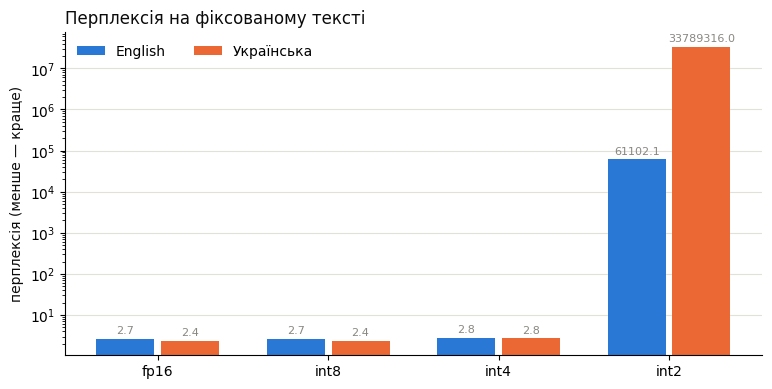

In [ ]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [ ]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",``thrown\nbetween 'ever'oft' \neverhosterone'...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}01\xb takent � taken...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0}'-'ever'ickets {'ever''}' \\'\...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.","}again \ %""樗\ %( firm \"" \ \'' betweenh '\ \..."
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...","fil��''}\n0. Heaven\n Fil'`0hber°,1 ,1a caught..."
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所etermineeverh \between betweenever婿 again \...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати лабораторну роботу до ...,"he economistwar"" be1.sever0 } again \ $} \}eve..."
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


In [ ]:
import random
random.seed(1)
words = PPL_TEXT["English"].split()          # слова з наявного тексту
random.shuffle(words)
shuffled = " ".join(words)                   # ті самі слова, але без змісту

model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE)
print("осмислений:", perplexity(model, PPL_TEXT["English"]))
print("випадковий:", perplexity(model, shuffled))

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

осмислений: 2.6729352474212646
випадковий: 261.3998107910156


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [ ]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з мінімальним використанням пам'яті. Це робиться для швидкого виконання моделей, особливо на пристроях з обмеженою відповідністю. Квантизація зменшує розмір ваг, змінюючи їх з плавних чисел (наприклад, 32-біт) до цілих або змінних (наприклад,

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [ ]:
VOTES = {1: "B", 2: "A", 3: "B", 4: "A", 5: "B"}

In [ ]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,int4
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,fp16
2,Explain in three sentences why the sky is blue.,fp16,int4,int4
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,int4
4,Write a Python function that checks whether a ...,int4,fp16,fp16


fp16 краща: 2, int4 краща: 3, однаково: 0


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [ ]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\\n again,  ten and whichotten in between win evidence tile between win had between between : : again again again again°\0 again which which had again between again again had again had had had had had had, which which again which9 which which in which   which in which in in in in which } in which Study which in which whichtbhousetbtbtbtbtbtbtbtb,househousehousehousehousehousehouse, in ...house doneettle,sdsdsdsd,uesdsdsd,sduesdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdificatesdsd: ...:’:ight ` which which “ which: which which which which which which which which which which which which which which which which which which which which which which which rest which which rest which resthouse :: which which again:sd: which

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\' \ \ \' 
 \ 0\' \ \'\'\'\'\'\'\'\'\'\' \ \ \ \ \ \ \ \ navigator \ \ 
 \ - DS  - - - - - - - - - - - - ~ ~ ~ taken  \ \ \ \ between \  hatchirst \ \\'\' \ - - - \INE \ \ -° - IN - between - found -国民  \ own%\ mark mark mark mark  mark mark mark             \ \          mark mark mark``h  \ mark mark mark mark mark  mark mark mark mark Mark Mark Mark Mark Mark attached  \ \  mark mark mark mark mark mark mark mark mark mark mark. mark mark mark, \ \ \ \ \n \   Paper mark, - \ mark\xb\xb \ \ - mark\n \ \ \ mark. \ Paper\n投 - \ \

## 3. Qwen3-1.7B

In [ ]:
SMALL_ID = "Qwen/Qwen3-1.7B"
small_tok = AutoTokenizer.from_pretrained(SMALL_ID)


def small_perplexity(model, text):
    ids = small_tok(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def small_translate(model, src, max_new_tokens=80):
    text = small_tok.apply_chat_template(
        [{"role": "user", "content": TRANSLATE_PROMPT.format(src)}],
        tokenize=False, add_generation_prompt=True, enable_thinking=False,
    )
    inputs = small_tok(text, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return small_tok.decode(out[0, inputs.input_ids.shape[1]:], skip_special_tokens=True).strip()


small_refs = [[ref] for _, ref in TRANSLATION]
small_records = {}

for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    model = AutoModelForCausalLM.from_pretrained(
        SMALL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config
    )
    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = small_perplexity(model, text)
    preds = [small_translate(model, src) for src, _ in TRANSLATION]
    r["chrF перекладу"] = chrf.compute(predictions=preds, references=small_refs)["score"]
    r["BLEU перекладу"] = bleu.compute(predictions=preds, references=small_refs)["score"]
    small_records[name] = r

    del model
    gc.collect()
    torch.cuda.empty_cache()
    print(f"{name}: готово")

small_summary = pd.DataFrame(small_records).T.round(2)
display(Markdown("**Qwen3-1.7B**"))
display(small_summary)

cols_ppl = [c for c in small_summary.columns if c.startswith("перплексія")]
comparison = pd.concat(
    {
        "1.7B: xPPL до fp16": small_summary[cols_ppl] / small_summary[cols_ppl].loc["fp16"],
        "4B: xPPL до fp16": summary[cols_ppl] / summary[cols_ppl].loc["fp16"],
    },
    axis=1,
).round(2)
comparison[("chrF", "1.7B")] = small_summary["chrF перекладу"]
comparison[("chrF", "4B")] = summary["chrF перекладу"]
display(Markdown("**Порівняння 1.7B і 4B (відносно fp16)**"))
display(comparison)

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

fp16: готово


... (6 outputs left out)

**Qwen3-1.7B**

,"памʼять моделі, GB","перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,3.45,4.35,3.09,48.98,24.11
int8,2.04,4.46,3.11,47.44,22.54
int4,1.38,7.51,5.61,29.71,4.59
int2,1.03,441276.94,5894554.50,0.24,0.00


**Порівняння 1.7B і 4B (відносно fp16)**

1.7B: ×PPL до fp16                           4B: ×PPL до fp16  \
     перплексія, English перплексія, Українська перплексія, English   
fp16                1.00                   1.00                1.00   
int8                1.03                   1.01                1.00   
int4                1.73                   1.82                1.05   
int2           101442.97             1907622.82            22884.69   

                              chrF         
     перплексія, Українська   1.7B     4B  
fp16                   1.00  48.98  56.71  
int8                   1.00  47.44  58.25  
int4                   1.15  29.71  55.90  
int2            14078881.67   0.24   0.24